# Forecasting net interest income

We construct an opening portfolio of 300 individual contracts: 120 fixed loans,
80 floating loans and 100 funding deposits. Loans have different origination
dates, maturities, notionals, coupon terms and repayment schedules. We size
deposit funding to the loans' current outstanding principal after contractual
amortization.

The forecast follows monthly interest income and funding expense for two years.
We compare runoff, replacement of repaid principal and replacement plus
quarterly growth under rate and funding-spread scenarios. Principal changes the
balance that earns interest; repayments do not count as income.

The notebook contains the complete forecasting implementation. QuantSupport
builds and prices each native contract. We use its fair-rate solver for new
business and calculate earned interest from the resolved coupon rate and
expected principal for each reporting month. The scope here is loans without
default and simple-interest term deposits, with Actual/360 or Actual/365
accrual.

The [loan notebook](../valuation/loans/loans.ipynb) covers the native instruments;
the [portfolio notebook](../sensitivity/portfolio.ipynb) covers their aggregation.

In [1]:
from __future__ import annotations

from bisect import bisect_right
from collections import defaultdict
from dataclasses import asdict, dataclass
from datetime import date, timedelta
import heapq
import math
import random
from typing import Sequence

import pandas as pd
import quantsupport as qs

## Normalize dates and validate numeric inputs

We use Python dates for the event queue and reporting periods, and convert
QuantSupport dates at the boundary. `_advance` delegates month arithmetic to
QuantSupport, so production tenors use the same date rules as the contracts.
`_finite` rejects invalid amounts and rates before they enter the ledgers.

In [2]:
def _date(value) -> date:
    return date.fromisoformat(str(value))


def _advance(value: date, months: int) -> date:
    return _date(qs.Date.parse(value.isoformat()).advance(months, "Months"))


def _finite(value: float, name: str, *, nonnegative: bool = False) -> None:
    if not math.isfinite(value) or (nonnegative and value < 0):
        raise ValueError(f"{name} must be finite" +
                         (" and nonnegative" if nonnegative else ""))

## Build projection and funding curves

EURIBOR3m projects floating resets and supplies the refinancing benchmark. ESTR
is the base funding curve. We add a term funding premium through a native
composite curve, `LOANFUNDING`, and select that curve in `fixed_income_policy`
for loan pricing. Term-deposit production also quotes against this funding
curve.

For new loan pricing, we enable `rebuild_amortization_for_fair_rate=True`: each
trial coupon or spread must rebuild the principal schedule, because a new French
loan's instalments depend on its agreed initial rate. Existing contracts keep
their agreed principal schedules when the market changes.

We add synthetic historical fixings while constructing the opening portfolio.
Scenarios change future curves while retaining those observed fixings. Parallel
rate shocks affect ESTR and EURIBOR once; a separate scenario widens only the
funding premium.

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

AS_OF = "2026-03-01"
HORIZON = "2028-03-01"
FUNDING_INDEX = qs.MarketIndex.other("LOANFUNDING")
FUNDING_SPREAD_INDEX = qs.MarketIndex.other("FUNDINGSPREAD")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

PILLARS = ["0D", "1Y", "2Y", "5Y", "10Y"]
ZERO_RATES = {
    "ESTR": [0.0225, 0.0230, 0.0240, 0.0260, 0.0280],
    "EURIBOR3m": [0.0270, 0.0280, 0.0300, 0.0320, 0.0340],
    "FUNDINGSPREAD": [0.0045, 0.0050, 0.0055, 0.0060, 0.0065],
}


def make_context():
    quotes = qs.QuoteStore.from_dict({
        "reference_date": AS_OF,
        "quotes": [
            {"identifier": f"ZeroRate_EUR_{index}_{tenor}", "mid": rate}
            for index, rates in ZERO_RATES.items()
            for tenor, rate in zip(PILLARS, rates)
        ],
    })
    curves = [qs.CurveConfiguration(
        market_index=FUNDING_SPREAD_INDEX if index == "FUNDINGSPREAD" else index,
        quotes=[f"ZeroRate_EUR_{index}_{tenor}" for tenor in PILLARS],
        day_counter="Actual360", interpolator="Linear",
    ) for index in ZERO_RATES]
    curves.append(qs.CurveConfiguration.composite(
        market_index=FUNDING_INDEX, base_index="ESTR", spread_index=FUNDING_SPREAD_INDEX,
    ))
    context = qs.PricingContext(
        quotes=quotes, curves=curves, fixings=qs.FixingStore(),
        csa_policy=qs.SingleCurveCSADiscountPolicy("EUR", "ESTR"),
        fixed_income_policy=qs.FixedIncomeDiscountPolicy({"EUR": FUNDING_INDEX}),
    )
    context.pricer_configurations = [qs.PricerConfiguration.loan(
        refinancing_benchmark_index="EURIBOR3m",
        rebuild_amortization_for_fair_rate=True,
    )]
    return context


pd.DataFrame(ZERO_RATES, index=PILLARS).rename_axis("zero-rate pillar")

,ESTR,EURIBOR3m,FUNDINGSPREAD
zero-rate pillar,,,
0D,0.02,0.03,0.00
1Y,0.02,0.03,0.01
2Y,0.02,0.03,0.01
5Y,0.03,0.03,0.01
10Y,0.03,0.03,0.01


## Keep each trade and its business segment

The forecast needs to know which principal receipts belong to which production
policy. A native `qs.Portfolio` aggregates compatible cashflows and does not
expose its member trades back to Python, so we retain the trades and segment
labels in `ForecastPortfolio` before aggregation.

`ForecastPosition` adds a name and a segment to a native `qs.Trade`. The
portfolio wrapper checks that names are unique and freezes the member list. We
use its `.native` property to construct the equivalent QuantSupport portfolio
for native aggregation. The native trades keep their position signs and notional
overrides.

In [4]:
@dataclass(frozen=True)
class ForecastPosition:
    """A native position plus the product group used for replacement rules."""

    name: str
    segment: str
    trade: qs.Trade


@dataclass(frozen=True)
class ForecastPortfolio:
    """Keep trade metadata alongside the equivalent native QS portfolio.

    QS Portfolio does not expose its member list to Python. Retain the trades
    here when building the book so that forecasts can attribute principal and
    income before native portfolio aggregation compresses compatible rows.
    """

    identifier: str
    positions: Sequence[ForecastPosition]

    def __post_init__(self):
        object.__setattr__(self, "positions", tuple(self.positions))
        names = [position.name for position in self.positions]
        if not self.identifier or not names or len(set(names)) != len(names):
            raise ValueError(
                "Provide a portfolio identifier and unique position names")
        if any(not p.name or not p.segment for p in self.positions):
            raise ValueError("Position names and segments must be nonempty")

    @property
    def native(self) -> qs.Portfolio:
        return qs.Portfolio(self.identifier, [p.trade for p in self.positions])

## Generate the opening positions

`generate_opening_portfolio` uses a seeded random generator so rerunning the
notebook gives the same contracts. Each loan is between one and 24 months old,
with its own notional, maturity, coupon basis and monthly or quarterly payments.
The repayment mix includes French amortization, bullet loans and 25% balloons.
Payment days are spread across the 1st, 10th and 20th of the month.

For floating loans we populate the historical observations requested by their
native schedules. We then evaluate future principal receipts to determine each
loan's current balance. Past contractual amortization has already reduced that
balance. The generated contracts assume no prepayments before the forecast date.
We apply each loan's prepayment model from that date onward.

Finally we create 100 individual term deposits with different rates and
maturities. Their total principal matches current loan assets. The inventory
below exposes the position count, balances and sample terms before any rollover
policy runs.

In [5]:
def generate_opening_portfolio(context, as_of, *, seed=42,
                               n_fixed=120, n_floating=80, n_deposits=100,
                               funding_index="ESTR"):
    """Generate individual seasoned contracts and match funding to current assets.

    Historical observations are synthetic, deterministic values for each date.
    Current balances follow contractual amortization; no past prepayment is assumed.
    Adds the observations to the supplied, inactive context before valuation.
    """
    as_of = _date(as_of)
    if any(not isinstance(n, int) or isinstance(n, bool) or n < 0
           for n in (n_fixed, n_floating, n_deposits)):
        raise ValueError("Position counts must be nonnegative integers")
    if n_fixed + n_floating == 0 or n_deposits == 0:
        raise ValueError("Generate at least one loan and one funding deposit")
    rng = random.Random(seed)
    positions, rows = [], []
    fixings = context.fixings or qs.FixingStore()

    def historical_rate(observed):
        observed = _date(observed)
        return 0.028 + 0.002 * math.sin((observed.year * 12 + observed.month) / 6)

    for rate_type, count, segment in [("fixed", n_fixed, "Fixed loans"),
                                       ("floating", n_floating, "Floating loans")]:
        for i in range(count):
            name = f"{rate_type}-{i + 1:04d}"
            start = _advance(as_of, -rng.randint(1, 24)).replace(day=rng.choice([1, 10, 20]))
            maturity = _advance(start, rng.choice([36, 48, 60, 84]))
            amount = rng.lognormvariate(math.log(250_000), 0.55)
            basis = rng.choice(["Actual360", "Actual365"])
            payments = rng.choice(["Monthly", "Quarterly"])
            repayment_name = rng.choices(["French", "Bullet", "Balloon"], [7, 1, 2])[0]
            repayment = (qs.LoanRepaymentStructure.balloon(0.25)
                         if repayment_name == "Balloon" else repayment_name)
            if rate_type == "fixed":
                quoted_rate = rng.uniform(0.035, 0.065)
                coupon = qs.FixedRateCoupon(rate=qs.InterestRate(
                    rate=quoted_rate, day_counter=basis, compounding="Simple"))
                initial_rate = quoted_rate
                prepayment = qs.PrepaymentModelConfiguration.refinancing_incentive(
                    base_cpr=0.03, incentive_multiplier=4.0, maximum_cpr=0.35)
            else:
                quoted_rate = rng.uniform(0.008, 0.022)
                coupon = qs.FloatingRateCoupon(index="EURIBOR3m", spread=quoted_rate,
                                               day_counter=basis)
                initial_rate = historical_rate(start) + quoted_rate
                prepayment = qs.PrepaymentModelConfiguration.constant_annual_cpr(
                    rng.uniform(0.02, 0.10))
            instrument = qs.Loan(
                identifier=name, start_date=start, maturity_date=maturity,
                notional=amount, currency="EUR", coupons=[coupon],
                repayment=repayment, payment_frequency=payments,
                fixing_frequency="Quarterly", index_tenor="3M", fixing_lag=0,
                calendar="NullCalendar", business_day_convention="Unadjusted",
                amortization_rate=initial_rate, prepayment=prepayment,
            )
            for observation in instrument.coupon_fixing_requests().itertuples(index=False):
                if _date(observation.fixing_date) < as_of:
                    fixings.add(observation.market_index, observation.fixing_date,
                                historical_rate(observation.fixing_date))
            positions.append(ForecastPosition(name, segment, qs.Trade(instrument, as_of)))
            rows.append(dict(position=name, segment=segment, rate_type=rate_type,
                             start_date=start, maturity_date=maturity, original_notional=amount,
                             contract_rate_or_spread=quoted_rate, repayment=repayment_name,
                             payment_frequency=payments, day_counter=basis))
    context.fixings = fixings
    with context:
        for position, row in zip(positions, rows):
            receipts = context.evaluate(position.trade, [qs.Request.Cashflows]).coupons
            row["current_principal"] = receipts.loc[receipts.type == "Redemption", "amount"].sum()
    assets = math.fsum(row["current_principal"] for row in rows)
    weights = [rng.lognormvariate(0, 0.6) for _ in range(n_deposits)]
    amounts = [assets * weight / math.fsum(weights) for weight in weights]
    amounts[-1] = assets - math.fsum(amounts[:-1])
    for i, amount in enumerate(amounts):
        name = f"funding-{i + 1:04d}"
        start = _advance(as_of, -rng.randint(1, 12)).replace(day=rng.choice([1, 10, 20]))
        maturity = _advance(as_of, rng.randint(1, 12)).replace(day=rng.choice([1, 10, 20]))
        rate = rng.uniform(0.012, 0.032)
        basis = rng.choice(["Actual360", "Actual365"])
        instrument = qs.FixedRateDeposit(
            identifier=name, start_date=start, maturity_date=maturity,
            notional=amount, rate=rate, currency="EUR", discount_index=funding_index,
            day_counter=basis, compounding="Simple",
        )
        positions.append(ForecastPosition(name, "Term funding", qs.Trade(instrument, as_of, "PayShort")))
        rows.append(dict(position=name, segment="Term funding", rate_type="fixed",
                         start_date=start, maturity_date=maturity, original_notional=amount,
                         contract_rate_or_spread=rate, repayment="Bullet",
                         payment_frequency="At maturity", day_counter=basis,
                         current_principal=amount))
    return ForecastPortfolio("EUR-BANK", positions), pd.DataFrame(rows)

In [6]:
context = make_context()
portfolio, opening_inventory = generate_opening_portfolio(
    context, AS_OF, seed=42, n_fixed=120, n_floating=80, n_deposits=100,
    funding_index=FUNDING_INDEX,
)
display(opening_inventory.groupby("segment").agg(
    positions=("position", "size"), current_principal_eur=("current_principal", "sum"),
    earliest_maturity=("maturity_date", "min"), latest_maturity=("maturity_date", "max"),
))
display(opening_inventory.groupby("segment", sort=False).head(3).style.format({
    "original_notional": "{:,.2f}", "current_principal": "{:,.2f}",
    "contract_rate_or_spread": "{:.4%}",
}))

,positions,current_principal_eur,earliest_maturity,latest_maturity
segment,,,,
Fixed loans,120,"28,525,412.91",2027-04-01,2033-02-01
Floating loans,80,"18,757,969.27",2027-04-20,2033-01-10
Term funding,100,"47,283,382.18",2026-04-01,2027-03-20


,position,segment,rate_type,start_date,maturity_date,original_notional,contract_rate_or_spread,repayment,payment_frequency,day_counter,current_principal
0,fixed-0001,Fixed loans,fixed,2024-06-01,2027-06-01,"338,082.08",6.1765%,French,Monthly,Actual360,"148,584.72"
1,fixed-0002,Fixed loans,fixed,2025-12-20,2032-12-20,"132,641.39",5.2678%,French,Quarterly,Actual360,"132,641.39"
2,fixed-0003,Fixed loans,fixed,2026-02-01,2033-02-01,"209,135.18",3.7901%,French,Monthly,Actual365,"206,904.94"
120,floating-0001,Floating loans,floating,2025-04-10,2032-04-10,"229,032.66",1.3240%,French,Quarterly,Actual365,"207,417.43"
121,floating-0002,Floating loans,floating,2024-11-01,2027-11-01,"485,195.84",2.0231%,French,Monthly,Actual365,"278,006.49"
122,floating-0003,Floating loans,floating,2025-01-20,2028-01-20,"179,436.97",1.1139%,French,Monthly,Actual360,"117,018.70"
200,funding-0001,Term funding,fixed,2025-06-10,2026-04-20,"441,272.91",1.2189%,Bullet,At maturity,Actual360,"441,272.91"
201,funding-0002,Term funding,fixed,2026-01-10,2026-10-20,"403,071.18",2.7688%,Bullet,At maturity,Actual360,"403,071.18"
202,funding-0003,Term funding,fixed,2025-06-01,2026-07-01,"410,883.81",3.0025%,Bullet,At maturity,Actual365,"410,883.81"


## Price new contracts

`ProductionTemplate` builds a unit contract with the requested tenor, coupon
frequency, repayment structure and prepayment model. `Request.FairRate(0)` then
solves its fixed coupon or floating spread using the native loan pricer and the
selected funding curve. A floating fair rate is a **spread**, not an all-in
rate. For a deposit we use its native fair-rate request, which includes its
initial advance.

We rebuild the zero-margin contract at that quote and reprice it. For a loan,
the PV of expected receipts must equal the discounted advance. For a deposit,
net PV must be zero. `par_error_bp` records that check before any commercial
margin is added. A single start-to-maturity forward would describe bullet
funding and would miss an amortizing loan's repayment and prepayment timing.

The commercial margin is added once to the solved coupon or spread. The native
constructor then builds the final schedule at that offer rate. For floating
loans we pass `context` to the constructor so its first index observation uses
native index conventions. This preserves the index's quotation and observation
conventions. `ProductionQuote` keeps the benchmark, margin and initial all-in
coupon separate in the output.

In [7]:
@dataclass(frozen=True)
class ProductionQuote:
    """Separate the par benchmark, commercial margin and initial all-in coupon."""

    quote_type: str
    par_quote: float
    commercial_margin: float
    contract_rate_or_spread: float
    initial_rate: float
    par_error_bp: float


@dataclass(frozen=True)
class ProductionTemplate:
    """Price an actual new contract with the native fair-rate solver.

    Fixed loans quote a coupon; floating loans quote a spread over their index.
    Loan discounting comes from context.fixed_income_policy. The index field
    selects floating observations or the discount index of a term deposit.
    """

    name: str
    kind: str = "loan"
    tenor_months: int = 24
    side: str = "LongReceive"
    currency: str = "EUR"
    rate_type: str = "fixed"
    index: str | qs.MarketIndex = "EURIBOR3m"
    margin: float = 0.015
    day_counter: str = "Actual365"
    repayment: str = "French"
    payment_frequency: str = "Monthly"
    fixing_frequency: str = "Quarterly"
    index_tenor_months: int = 3
    prepayment: qs.PrepaymentModelConfiguration | None = None

    def __post_init__(self):
        if not self.name or self.kind not in ("loan", "deposit"):
            raise ValueError("A template needs a name and kind 'loan' or 'deposit'")
        if self.side not in ("LongReceive", "PayShort"):
            raise ValueError("Use LongReceive for assets or PayShort for liabilities")
        if self.rate_type not in ("fixed", "floating"):
            raise ValueError("rate_type must be fixed or floating")
        if self.kind == "deposit" and (self.rate_type != "fixed" or self.prepayment is not None):
            raise ValueError("Term deposits support fixed rates and no prepayment model")
        for name in ("tenor_months", "index_tenor_months"):
            value = getattr(self, name)
            if not isinstance(value, int) or isinstance(value, bool) or value <= 0:
                raise ValueError(f"{name} must be a positive integer")
        _finite(self.margin, "margin")
        qs.DayCounter.parse(self.day_counter)

    def _instrument(self, context, identifier, start, amount, quoted_rate):
        common = dict(identifier=identifier, start_date=start,
                      maturity_date=_advance(start, self.tenor_months),
                      notional=amount, currency=self.currency)
        if self.kind == "deposit":
            return qs.FixedRateDeposit(
                **common, rate=quoted_rate, discount_index=self.index,
                day_counter=self.day_counter, compounding="Simple",
            )
        coupon = (
            qs.FixedRateCoupon(rate=qs.InterestRate(
                rate=quoted_rate, day_counter=self.day_counter, compounding="Simple",
            )) if self.rate_type == "fixed" else qs.FloatingRateCoupon(
                index=self.index, spread=quoted_rate, day_counter=self.day_counter,
            )
        )
        return qs.Loan(
            **common, coupons=[coupon], repayment=self.repayment,
            payment_frequency=self.payment_frequency,
            fixing_frequency=self.fixing_frequency,
            index_tenor=f"{self.index_tenor_months}M", prepayment=self.prepayment,
            calendar="NullCalendar", business_day_convention="Unadjusted", fixing_lag=0,
            # Resolve the first index observation using the loan's own conventions.
            # Native construction sets amortization from the initial all-in coupon.
            context=context,
        )

    def quote(self, context: qs.PricingContext, start: date) -> ProductionQuote:
        """Solve a unit contract at par, then add the commercial margin once."""
        if self.kind == "loan":
            configurations = [item.to_dict() for item in context.pricer_configurations]
            rebuild = any(item.get("pricer", {}).get("Loan", {}).get(
                "rebuild_amortization_for_fair_rate", False)
                for item in configurations if isinstance(item.get("pricer"), dict))
            if not rebuild:
                raise ValueError("New loan pricing requires rebuild_amortization_for_fair_rate=True")
            policy = context.fixed_income_policy
            if policy is None:
                raise ValueError("Set an explicit fixed_income_policy for new loan pricing")
            discount_index = policy.to_dict()["discount_curve_by_currency"][self.currency]
        else:
            discount_index = self.index
        name = f"{self.name}-quote-{start.isoformat()}"
        seed_quote = 0.0 if self.rate_type == "floating" else 0.03
        seed = self._instrument(context, name, start, 1.0, seed_quote)
        par = context.evaluate(qs.Trade(seed, start), [qs.Request.FairRate(0)]).fair_rate
        at_par = self._instrument(context, name, start, 1.0, par)
        value = context.evaluate(qs.Trade(at_par, start), [qs.Request.Value]).price
        curve = context.curve(discount_index)
        advance_pv = curve.discount_factor(start) / curve.discount_factor(context.evaluation_date)
        # Loan Value reports receipts; deposit Value already subtracts its advance.
        residual = value - advance_pv if self.kind == "loan" else value
        error_bp = residual / advance_pv * 10_000
        if abs(error_bp) > 1e-5:
            raise ValueError(f"The rebuilt par contract has a pricing residual of {error_bp} bp")
        contract_quote = par + self.margin
        final = self._instrument(context, name, start, 1.0, contract_quote)
        initial = final.to_dict()["amortization_rate"] if self.kind == "loan" else contract_quote
        quote_type = "floating_spread" if self.rate_type == "floating" else "fixed_coupon"
        return ProductionQuote(quote_type, par, self.margin, contract_quote, initial, error_bp)

    def build(self, context: qs.PricingContext, identifier: str,
              start: date, amount: float, *, quote: ProductionQuote | None = None):
        """Build a new native position from a quote for this date and scenario."""
        quote = self.quote(context, start) if quote is None else quote
        instrument = self._instrument(context, identifier, start, amount,
                                      quote.contract_rate_or_spread)
        return qs.Trade(instrument, start, self.side), quote

## Describe replacement and additional production separately

`RolloverRule` links a segment to its replacement template. We give scheduled
principal and prepayments separate replacement fractions, because the business
may retain those amounts at different rates. A fraction of one replaces the full
amount; `lag_days` delays the origination after repayment.

`NewProduction` is an additional dated order. Keeping it separate from
replacement prevents a growth target from being confused with the volume
needed to maintain the existing balance. Once either kind of order creates a
cohort, that cohort follows its segment's rollover rule too.

In [8]:
@dataclass(frozen=True)
class RolloverRule:
    """Replace scheduled principal (including maturity) and prepayments separately.

    The rule also applies to its replacement cohorts. With both fractions one,
    zero lag, and the same balance-sheet side, the segment balance stays constant.
    """

    segment: str
    template: ProductionTemplate
    scheduled_fraction: float = 1.0
    prepayment_fraction: float = 1.0
    lag_days: int = 0

    def __post_init__(self):
        if not self.segment:
            raise ValueError("A rollover rule needs a segment")
        for name in ("scheduled_fraction", "prepayment_fraction"):
            value = getattr(self, name)
            _finite(value, name)
            if not 0 <= value <= 1:
                raise ValueError(f"{name} must lie in [0, 1]")
        if not isinstance(self.lag_days, int) or isinstance(self.lag_days, bool) or self.lag_days < 0:
            raise ValueError("lag_days must be a nonnegative integer")


@dataclass(frozen=True)
class NewProduction:
    """An additional origination, independent of principal replacement."""

    date: date | str
    amount: float
    segment: str
    template: ProductionTemplate

    def __post_init__(self):
        object.__setattr__(self, "date", _date(self.date))
        _finite(self.amount, "production amount", nonnegative=True)
        if not self.segment:
            raise ValueError("New production needs a segment")

## Set replacement terms and the growth plan

We replace scheduled principal and prepayments immediately in all three
segments. Fixed lending uses a 24-month French loan with a 140 bp commercial
margin over its native par coupon. Floating lending adds 150 bp to its native
par spread over EURIBOR3m. Funding renews for three months at the native deposit
par rate less 40 bp. New contracts use unadjusted dates and zero fixing lag
here.

Growth adds EUR 1 million of floating loans and matching term funding each quarter,
starting three months into the forecast. Planned cohorts also follow their
segment's rollover rule. Runoff, replacement and growth are separate balance
policies; these are common [earnings measurement views](https://www.bis.org/basel_framework/chapter/SRP/98.htm?inforce=20191215&published=20191215&tldate=20191031).

In [9]:
refinancing = qs.PrepaymentModelConfiguration.refinancing_incentive(
    base_cpr=0.03, incentive_multiplier=4.0, maximum_cpr=0.35,
)
floating_cpr = qs.PrepaymentModelConfiguration.constant_annual_cpr(0.06)
fixed_production = ProductionTemplate(
    "24m fixed lending", tenor_months=24, margin=0.014, prepayment=refinancing,
)
floating_production = ProductionTemplate(
    "24m floating lending", tenor_months=24, rate_type="floating",
    index="EURIBOR3m", margin=0.015, day_counter="Actual360", prepayment=floating_cpr,
)
funding_production = ProductionTemplate(
    "3m term funding", kind="deposit", tenor_months=3, side="PayShort",
    index=FUNDING_INDEX, margin=-0.004, day_counter="Actual365",
)
rollovers = [RolloverRule("Fixed loans", fixed_production),
             RolloverRule("Floating loans", floating_production),
             RolloverRule("Term funding", funding_production)]
growth = []
for month in range(3, 24, 3):
    start = str(qs.Date.parse(AS_OF).advance(month, "Months"))
    growth.extend([NewProduction(start, 1_000_000, "Floating loans", floating_production),
                   NewProduction(start, 1_000_000, "Term funding", funding_production)])
pd.DataFrame([dict(date=p.date, segment=p.segment, amount_eur=p.amount, template=p.template.name)
              for p in growth])

,date,segment,amount_eur,template
0,2026-06-01,Floating loans,1000000,24m floating lending
1,2026-06-01,Term funding,1000000,3m term funding
2,2026-09-01,Floating loans,1000000,24m floating lending
3,2026-09-01,Term funding,1000000,3m term funding
4,2026-12-01,Floating loans,1000000,24m floating lending
5,2026-12-01,Term funding,1000000,3m term funding
6,2027-03-01,Floating loans,1000000,24m floating lending
7,2027-03-01,Term funding,1000000,3m term funding
8,2027-06-01,Floating loans,1000000,24m floating lending
9,2027-06-01,Term funding,1000000,3m term funding


## Calculate earned interest from the resolved coupon

`_cashflows` asks QuantSupport for expected loan receipts. Each coupon row
contains its resolved rate, accrual dates and **signed expected principal**,
already reduced by earlier projected prepayments. Prepayment occurs at scheduled
payment dates, after that period's interest and scheduled principal. Fixed
coupons use `rate`; floating coupons use `fixing + spread`. We use the signed
expected notionals directly in monthly accrual.

For every coupon/month overlap, `_accrue` calculates:

$$I = N_{expected} \times r_{all-in} \times \operatorname{yearFraction}(left, right).$$

`left` is the later of the coupon start and reporting-period start; `right` is the
earlier of their end dates. The day count comes from the coupon. This is the native
linear coupon accrual formula, applied to the overlap, with no division by the full
coupon amount or its full-period accrual fraction. Both Actual/360 and Actual/365
are additive across these reporting boundaries. The detail table retains principal,
rate, dates and year fraction alongside every interest amount.

A deposit's maturity coupon can span several reporting months, including months
before the forecast date. We calculate only the interest earned within the
forecast. Its historical advance is excluded from receipt extraction. Coupons
paid after the horizon still contribute the portion earned before the horizon.

`_balances` keeps principal separate:
`closing = opening + production - scheduled_principal - prepayment`.
Principal events belong to `(period_start, period_end]`; interest uses
`[period_start, period_end)`. Production on the forecast date is included in the
first period. Production on the horizon date changes the closing balance but earns
no interest within the horizon.

In [10]:
@dataclass
class ForecastResult:
    """Undiscounted income, positive asset/liability balances and audit tables."""

    monthly: pd.DataFrame
    income_detail: pd.DataFrame
    balances: pd.DataFrame
    productions: pd.DataFrame
    cashflows: pd.DataFrame


class _IncomeAccounting:
    """Read native receipts and maintain the monthly income and balance ledgers."""

    def __init__(self, as_of, horizon, currency="EUR"):
        self.as_of, self.horizon = _date(as_of), _date(horizon)
        self.currency = str(currency)
        if self.horizon <= self.as_of:
            raise ValueError("The forecast horizon must follow as_of")
        self.periods = []
        start = self.as_of
        while start < self.horizon:
            following = date(start.year + start.month //
                             12, start.month % 12 + 1, 1)
            end = min(following, self.horizon)
            self.periods.append((start, end))
            start = end
        self.period_ends = [end for _, end in self.periods]

    @staticmethod
    def _cashflows(context: qs.PricingContext, trade: qs.Trade) -> pd.DataFrame:
        """Return signed coupon/principal receipts in the native coupon schema.

        Initial advances belong to the production ledger. Keep full coupon
        accrual dates here; the caller filters payments and allocates only the
        interest earned within the forecast. Loan rows already include native
        prepayment adjustments and position signs.
        """
        instrument = trade.instrument
        if isinstance(instrument, qs.Loan):
            return context.evaluate(trade, [qs.Request.Cashflows]).coupons.copy()
        if not isinstance(instrument, qs.FixedRateDeposit):
            raise ValueError(
                "This example supports Loan and FixedRateDeposit positions")
        # Native DCF valuation includes the deposit's historical advance. For an
        # income forecast, request only its contractual receipt economics using
        # a native coupon, avoiding discounting cash paid before the curve date.
        terms = instrument.to_dict()
        if terms["compounding"] != "Simple":
            raise ValueError("Monthly allocation requires simple-interest coupons")
        amount = instrument.notional if trade.notional is None else trade.notional
        direction = 1 if trade.side == qs.Side.LongReceive else -1
        rate = qs.InterestRate(
            rate=terms["rate"], day_counter=terms["day_counter"],
            compounding=terms["compounding"], frequency=terms["rate_frequency"],
        )
        coupon = qs.FixedRateCoupon(
            rate=rate, notional=1.0, accrual_start_date=terms["start_date"],
            accrual_end_date=terms["maturity_date"], payment_date=terms["maturity_date"],
        )
        common = dict(payment_date=terms["maturity_date"], currency=terms["currency"],
                      leg_index=0, fixing=None)
        accrual = qs.DayCounter.parse(terms["day_counter"]).year_fraction(
            terms["start_date"], terms["maturity_date"],
        )
        details = dict(
            accrual_start=terms["start_date"], accrual_end=terms["maturity_date"],
            market_index=None, notional=amount * direction, rate=terms["rate"],
            spread=None, day_counter=terms["day_counter"],
            rate_definition=rate.to_dict()["rate_definition"],
        )
        # Let the binding supply its standard columns and metadata formatting.
        result = qs.EvaluationResults(
            evaluation_date=context.evaluation_date, identifier=instrument.identifier,
            cashflows=[
                dict(common, type="FixedRateCoupon", amount=coupon.amount() * amount * direction,
                     accrual_period=accrual, coupon_details=details),
                dict(common, type="Redemption", amount=amount * direction),
            ],
        )
        return result.coupons

    def _validate_trade(self, trade):
        instrument = trade.instrument
        if not isinstance(instrument, (qs.Loan, qs.FixedRateDeposit)):
            raise ValueError(
                "This example supports Loan and FixedRateDeposit positions")
        terms = instrument.to_dict()
        if terms["currency"] != self.currency:
            raise ValueError(
                "Position currency must match the forecast currency")
        if isinstance(instrument, qs.Loan):
            if terms.get("credit_index") is not None:
                raise ValueError(
                    "Default/recovery accounting is outside this example")
            fixed = [coupon["FixedRateCoupon"]["rate"]["rate_definition"]["compounding"]
                     for coupon in terms["coupons"] if "FixedRateCoupon" in coupon]
        else:
            fixed = [terms["compounding"]]
        if any(compounding != "Simple" for compounding in fixed):
            raise ValueError(
                "Monthly allocation requires simple-interest coupons")
        return "asset" if trade.side == qs.Side.LongReceive else "liability"

    def _accrue(self, table, output):
        for row in table.itertuples(index=False):
            if row.type == "Redemption":
                continue
            if row.type == "FixedRateCoupon":
                annual_rate = row.rate
            elif row.type == "FloatingRateCoupon":
                annual_rate = row.fixing + row.spread
            else:
                raise ValueError("Accrual supports fixed and floating coupons only")
            if row.day_counter not in ("Actual360", "Actual365"):
                raise ValueError("This forecast uses Actual360 or Actual365 accrual")
            start, end = _date(row.accrual_start), _date(row.accrual_end)
            dc = qs.DayCounter.parse(row.day_counter)
            # Native receipt notionals already include expected prepayment and side.
            expected_principal = row.notional
            first = bisect_right(self.period_ends, start)
            for period_start, period_end in self.periods[first:]:
                if period_start >= end:
                    break
                left, right = max(start, period_start), min(end, period_end)
                if right <= left:
                    continue
                fraction = dc.year_fraction(left, right)
                interest = expected_principal * annual_rate * fraction
                output.append(dict(
                    period_start=period_start, period_end=period_end,
                    cohort=row.cohort, position=row.position, segment=row.segment,
                    origin=row.origin, book_side=row.book_side,
                    accrual_start=left, accrual_end=right, day_counter=row.day_counter,
                    expected_principal=expected_principal, annual_rate=annual_rate,
                    year_fraction=fraction, interest=interest,
                ))

    def _balances(self, openings, movements):
        opening = defaultdict(float)
        for row in openings:
            opening[(row["segment"], row["book_side"])] += row["amount"]
        grouped = defaultdict(list)
        for row in movements:
            grouped[(row["segment"], row["book_side"])].append(row)
        rows = []
        for segment, side in sorted(set(opening) | set(grouped)):
            balance = opening[(segment, side)]
            for start, end in self.periods:
                amounts = defaultdict(float)
                for event in grouped[(segment, side)]:
                    if (start < event["date"] <= end or event["date"] == start == self.as_of):
                        amounts[event["kind"]] += event["amount"]
                closing = balance + amounts["production"] - \
                    amounts["scheduled"] - amounts["prepayment"]
                rows.append(dict(period_start=start, period_end=end, segment=segment,
                                 book_side=side, opening_balance=balance,
                                 scheduled_principal=amounts["scheduled"], prepayment=amounts["prepayment"],
                                 production=amounts["production"], closing_balance=closing))
                balance = closing
        return pd.DataFrame(rows)

## Process originations and repayments in date order

`IncomeForecaster.forecast` starts with fresh ledgers on every call. We project
each existing trade once under the active market and put its principal events
into a date queue. This retains the native prepayment projection for the whole
cohort instead of restarting it at each reporting month.

The nested `project` function records the cohort's receipts, accrues its
interest, and schedules its principal movements. The event loop takes the
earliest date, converts eligible repayments into replacement orders, and adds
any planned orders due that day. Orders with the same segment, template and
origin are pooled before building a new trade. Its repayments then enter the
same queue, which makes replacement recursive without creating a separate
cohort for every ancestor repayment.

Quotes are reused only for the same template and origination date inside one
forecast. A new scenario starts with an empty quote cache, so benchmark rates
are solved again against that scenario's curves.

Once the queue reaches the horizon, we aggregate signed interest into income and
expense, calculate NII, and return the detailed ledgers alongside those totals.
Principal cash is tracked separately so an unfunded balance cannot be mistaken
for interest income.

In [11]:
class IncomeForecaster(_IncomeAccounting):
    """Project each cohort once, then process dated runoff and production events.

    Accrual periods are [start, end). Balance movements are (start, end], with
    production on the forecast date included in the first period. Production on
    the horizon date affects closing balances but earns no in-horizon interest.
    All amounts retain the forecast currency; there is no implicit FX conversion.
    """

    def forecast(self, context: qs.PricingContext, portfolio: ForecastPortfolio, *,
                 rollovers: Sequence[RolloverRule] = (),
                 planned: Sequence[NewProduction] = ()) -> ForecastResult:
        """Evaluate inside an active QS context, including an optional Scenario scope.

        Existing trades must already represent current contractual balances and
        actual historical prepayments. We do not reconstruct those from CPR.
        Each call starts fresh; neither input positions nor prior results mutate.
        """
        if _date(context.evaluation_date) != self.as_of:
            raise ValueError(
                "PricingContext evaluation_date must equal forecast as_of")
        rules = {rule.segment: rule for rule in rollovers}
        if len(rules) != len(rollovers):
            raise ValueError("Use at most one rollover rule per segment")
        segments = {p.segment for p in portfolio.positions} | {
            p.segment for p in planned}
        if not set(rules).issubset(segments):
            raise ValueError(
                "Rollover segments must occur in the portfolio or production plan")
        for template in [r.template for r in rollovers] + [p.template for p in planned]:
            if str(template.currency) != self.currency:
                raise ValueError(
                    "Production currency must match the forecast currency")

        dates, events = [], {}
        frames, income, movements, openings, production = [], [], [], [], []
        segment_sides = {}
        cohort_number = 0
        quotes = {}  # Local to this forecast: no quote survives a scenario change.

        def enqueue(when, kind, payload):
            if when > self.horizon:
                return
            if when not in events:
                events[when] = []
                heapq.heappush(dates, when)
            events[when].append((kind, payload))

        def project(position, origin, start):
            nonlocal cohort_number
            cohort_number += 1
            cohort = f"{origin}-{cohort_number:04d}"
            side = self._validate_trade(position.trade)
            if origin == "existing" and _date(position.trade.instrument.start_date) > self.as_of:
                raise ValueError(
                    "Future originations belong in planned production")
            previous_side = segment_sides.setdefault(position.segment, side)
            if previous_side != side:
                raise ValueError(
                    "A segment must contain only assets or only liabilities")
            rule = rules.get(position.segment)
            if rule and (rule.template.side == "LongReceive") != (side == "asset"):
                raise ValueError(
                    "A rollover must preserve its segment's asset/liability side")
            table = self._cashflows(context, position.trade)
            table = table[table.payment_date > self.as_of.isoformat()].copy()
            if not set(table.currency).issubset({self.currency}):
                raise ValueError(
                    "Cashflow currency must match the forecast currency")
            table["cohort"], table["position"] = cohort, position.name
            table["segment"], table["origin"], table["book_side"] = position.segment, origin, side
            frames.append(table)
            self._accrue(table, income)
            principal = table[table.type == "Redemption"]
            direction = 1 if side == "asset" else -1
            amounts = principal.amount * direction
            if (amounts < -1e-8).any():
                raise ValueError(
                    "Principal direction must agree with the position side")
            balance = math.fsum(amounts)
            if origin == "existing":
                openings.append(dict(segment=position.segment,
                                book_side=side, amount=balance))
            else:
                movements.append(dict(date=start, segment=position.segment, book_side=side,
                                      kind="production", amount=balance))
            for row in principal.itertuples(index=False):
                when = _date(row.payment_date)
                if when <= start and origin != "existing":
                    raise ValueError(
                        "A new cohort must repay principal after its origination")
                is_prepayment = isinstance(
                    position.trade.instrument, qs.Loan) and row.leg_index == 1
                kind = "prepayment" if is_prepayment else "scheduled"
                amount = row.amount * direction
                if when <= self.horizon:
                    movements.append(dict(date=when, segment=position.segment,
                                          book_side=side, kind=kind, amount=amount))
                    enqueue(when, "principal",
                            (position.segment, kind, amount))
            return cohort

        for position in portfolio.positions:
            project(position, "existing", self.as_of)
        for order in planned:
            if not self.as_of <= order.date <= self.horizon:
                raise ValueError(
                    "Planned production must fall within the forecast dates")
            enqueue(order.date, "production", (order.segment,
                    "planned", order.template, order.amount))

        while dates:
            when = heapq.heappop(dates)
            batch = events.pop(when)
            orders = []
            for kind, payload in batch:
                if kind == "production":
                    orders.append(payload)
                    continue
                segment, principal_kind, amount = payload
                if segment not in rules:
                    continue
                rule = rules[segment]
                fraction = rule.prepayment_fraction if principal_kind == "prepayment" else rule.scheduled_fraction
                replacement = (segment, "replacement",
                               rule.template, amount * fraction)
                start = when + timedelta(days=rule.lag_days)
                if start == when:
                    orders.append(replacement)
                else:
                    enqueue(start, "production", replacement)
            # Pool same-day orders to avoid branching once per ancestor cohort.
            grouped = {}
            for segment, origin, template, amount in orders:
                key = (segment, origin, id(template))
                if key not in grouped:
                    grouped[key] = [template, []]
                grouped[key][1].append(amount)
            for (segment, origin, _), (template, amounts) in grouped.items():
                amount = math.fsum(amounts)
                if amount == 0:
                    continue
                identifier = f"{portfolio.identifier}-{origin}-{cohort_number + 1:04d}"
                quote_key = (id(template), when)
                if quote_key not in quotes:
                    quotes[quote_key] = template.quote(context, when)
                trade, quote = template.build(context, identifier, when, amount,
                                               quote=quotes[quote_key])
                cohort = project(ForecastPosition(
                    identifier, segment, trade), origin, when)
                production.append(dict(date=when, segment=segment, origin=origin,
                                       cohort=cohort, template=template.name, amount=amount,
                                       **asdict(quote),
                                       maturity_date=_date(trade.instrument.maturity_date)))

        detail = pd.DataFrame(income, columns=[
            "period_start", "period_end", "cohort", "position", "segment",
            "origin", "book_side", "accrual_start", "accrual_end", "day_counter",
            "expected_principal", "annual_rate", "year_fraction", "interest",
        ])
        balances = self._balances(openings, movements)
        monthly = pd.DataFrame(self.periods, columns=[
                               "period_start", "period_end"])
        for side, column, sign in [("asset", "interest_income", 1), ("liability", "interest_expense", -1)]:
            totals = detail[detail.book_side == side].groupby(
                "period_start").interest.sum()
            monthly[column] = monthly.period_start.map(
                totals).fillna(0.0) * sign
            totals = balances[balances.book_side == side].groupby(
                "period_start").closing_balance.sum()
            monthly[f"{side}_balance"] = monthly.period_start.map(
                totals).fillna(0.0)
        monthly["nii"] = monthly.interest_income - monthly.interest_expense
        monthly["cumulative_nii"] = monthly.nii.cumsum()
        principal_cash = (
            balances.scheduled_principal + balances.prepayment - balances.production
        ) * balances.book_side.map({"asset": 1, "liability": -1})
        cash = balances.assign(cash=principal_cash).groupby(
            "period_start").cash.sum()
        monthly["net_principal_cashflow"] = monthly.period_start.map(
            cash).fillna(0.0)
        monthly["cumulative_principal_cash"] = monthly.net_principal_cashflow.cumsum()
        productions = pd.DataFrame(production, columns=[
            "date", "segment", "origin", "cohort", "template", "amount",
            "quote_type", "par_quote", "commercial_margin", "contract_rate_or_spread",
            "initial_rate", "par_error_bp", "maturity_date",
        ])
        return ForecastResult(monthly, detail, balances, productions, pd.concat(frames, ignore_index=True))

## Run the three production policies under each rate scenario

We call the same forecaster with no production rules for runoff, with rollover
rules for replacement, and with both rollover rules and planned orders for
growth. Each call runs inside its scenario scope so floating resets, refinancing
CPR and new-business pricing all see the same shocked curves.

The original contracts and observed fixings stay in place. An existing fixed
coupon therefore keeps its rate while a replacement fixed loan takes the rate
calculated from its scenario curve. The difference between scenario NII totals
comes from rerunning that forecast, rather than substituting a PV sensitivity.

In [12]:
forecaster = IncomeForecaster(AS_OF, HORIZON, currency="EUR")
modes = {"Runoff": dict(), "Replacement": dict(rollovers=rollovers),
         "Growth": dict(rollovers=rollovers, planned=growth)}
scenario_shocks = {
    "Base": [],
    "Up 100 bp": [qs.Shock(index, 0.01, qs.ScenarioType.Absolute)
                  for index in ["ESTR", "EURIBOR3m"]],
    "Down 100 bp": [qs.Shock(index, -0.01, qs.ScenarioType.Absolute)
                    for index in ["ESTR", "EURIBOR3m"]],
    "Funding +50 bp": [qs.Shock("FUNDINGSPREAD", 0.005, qs.ScenarioType.Absolute)],
}
results = {}
with context:
    for scenario_name, shocks in scenario_shocks.items():
        with qs.Scenario(shocks=shocks):
            for mode, settings in modes.items():
                results[(scenario_name, mode)] = forecaster.forecast(context, portfolio, **settings)

summary = pd.DataFrame([
    {"scenario": scenario, "mode": mode, "two_year_nii_eur": result.monthly.nii.sum(),
     "delta_nii_eur": result.monthly.nii.sum() - results[("Base", mode)].monthly.nii.sum(),
     "closing_assets_eur": result.monthly.asset_balance.iloc[-1],
     "closing_liabilities_eur": result.monthly.liability_balance.iloc[-1],
     "new_cohorts": len(result.productions)}
    for (scenario, mode), result in results.items()
])
summary

,scenario,mode,two_year_nii_eur,delta_nii_eur,closing_assets_eur,closing_liabilities_eur,new_cohorts
0,Base,Runoff,"2,696,176.10",0.00,"19,962,071.24",-0.00,0
1,Base,Replacement,"2,143,447.27",0.00,"47,283,382.18","47,283,382.18",213
2,Base,Growth,"2,279,133.58",0.00,"54,283,382.18","54,283,382.18",227
3,Up 100 bp,Runoff,"3,024,256.22","328,080.12","20,997,218.64",-0.00,0
4,Up 100 bp,Replacement,"1,978,553.86","-164,893.41","47,283,382.18","47,283,382.18",213
5,Up 100 bp,Growth,"2,113,813.66","-165,319.92","54,283,382.18","54,283,382.18",227
6,Down 100 bp,Runoff,"2,369,084.07","-327,092.03","18,954,068.82",-0.00,0
7,Down 100 bp,Replacement,"2,279,231.19","135,783.92","47,283,382.18","47,283,382.18",213
8,Down 100 bp,Growth,"2,415,222.93","136,089.35","54,283,382.18","54,283,382.18",227
9,Funding +50 bp,Runoff,"2,696,176.10",0.00,"19,962,071.24",-0.00,0


## Inspect the rates used for new positions

We compare quotes on the first growth date so every scenario uses the same start
and tenor. `par_quote` is a fixed coupon or a floating spread, as shown by
`quote_type`. We add `commercial_margin` once to obtain the contractual quote.
`initial_rate` is the resulting all-in coupon; for a floating loan the native
constructor resolves the first index observation and adds the quoted spread.

`par_error_bp` reprices the zero-margin contract and measures its residual against
the discounted advance. The margin-bearing offer is not expected to have zero
NPV. This table also shows whether a funding-spread shock passes through to the
new loan and deposit quotes.

In [13]:
quote_date = _date(growth[0].date)
pricing_audit = pd.concat([
    result.productions.assign(scenario=scenario)
    for (scenario, mode), result in results.items() if mode == "Growth"
], ignore_index=True)
display(pricing_audit.loc[pricing_audit.date == quote_date, [
    "scenario", "template", "quote_type", "par_quote", "commercial_margin",
    "contract_rate_or_spread", "initial_rate", "par_error_bp",
]].drop_duplicates(["scenario", "template", "quote_type"]).style.format({
    "par_quote": "{:.4%}", "commercial_margin": "{:.4%}",
    "contract_rate_or_spread": "{:.4%}", "initial_rate": "{:.4%}",
    "par_error_bp": "{:.8f}",
}))

,scenario,template,quote_type,par_quote,commercial_margin,contract_rate_or_spread,initial_rate,par_error_bp
21,Base,24m fixed lending,fixed_coupon,2.9620%,1.4000%,4.3620%,4.3620%,-0.00000003
22,Base,24m floating lending,floating_spread,-0.0418%,1.5000%,1.4582%,4.2437%,0.00000008
23,Base,3m term funding,fixed_coupon,2.8242%,-0.4000%,2.4242%,2.4242%,0.00000000
248,Up 100 bp,24m fixed lending,fixed_coupon,3.9784%,1.4000%,5.3784%,5.3784%,0.00000004
249,Up 100 bp,24m floating lending,floating_spread,-0.0476%,1.5000%,1.4524%,5.2463%,-0.00000009
250,Up 100 bp,3m term funding,fixed_coupon,3.8466%,-0.4000%,3.4466%,3.4466%,0.00000000
475,Down 100 bp,24m fixed lending,fixed_coupon,1.9463%,1.4000%,3.3463%,3.3463%,-0.00000004
476,Down 100 bp,24m floating lending,floating_spread,-0.0377%,1.5000%,1.4623%,3.2420%,-0.00000004
477,Down 100 bp,3m term funding,fixed_coupon,1.8044%,-0.4000%,1.4044%,1.4044%,0.00000000
702,Funding +50 bp,24m fixed lending,fixed_coupon,3.4690%,1.4000%,4.8690%,4.8690%,0.00000001


## Read monthly income alongside the funding balance

We start with the base growth result, then plot all three production policies.
`interest_income` and `interest_expense` are the accrued asset and funding
amounts for each month; their difference is `nii`. The balance curves show how
runoff, renewal and additional production change the book that earns that
income.

We also plot `cumulative_principal_cash`. In the runoff case, funding can mature
before the assets repay. A negative value shows the funding requirement, but the
cash ledger itself earns no interest and charges no financing cost here.
Including that cost requires explicit treasury funding trades. The matched loan
and deposit orders keep replacement and growth funded in these cases.

,period_start,period_end,interest_income,asset_balance,interest_expense,liability_balance,nii,cumulative_nii,net_principal_cashflow,cumulative_principal_cash
0,2026-03-01,2026-04-01,"195,688.70","47,283,382.18","91,401.95","47,283,382.18","104,286.75","104,286.75",0.00,0.00
1,2026-04-01,2026-05-01,"189,048.04","47,283,382.18","88,688.23","47,283,382.18","100,359.81","204,646.56",0.00,0.00
2,2026-05-01,2026-06-01,"194,842.46","48,283,382.18","92,402.62","48,283,382.18","102,439.84","307,086.41",-0.00,-0.00
3,2026-06-01,2026-07-01,"191,662.98","48,283,382.18","92,241.73","48,283,382.18","99,421.25","406,507.66",-0.00,-0.00
4,2026-07-01,2026-08-01,"197,641.20","48,283,382.18","96,180.29","48,283,382.18","101,460.92","507,968.57",-0.00,-0.00
5,2026-08-01,2026-09-01,"197,227.40","49,283,382.18","96,834.34","49,283,382.18","100,393.06","608,361.64",0.00,-0.00
6,2026-09-01,2026-10-01,"194,131.95","49,283,382.18","96,411.52","49,283,382.18","97,720.43","706,082.07",0.00,-0.00
7,2026-10-01,2026-11-01,"200,285.22","49,283,382.18","100,711.47","49,283,382.18","99,573.75","805,655.82",-0.00,-0.00
8,2026-11-01,2026-12-01,"193,521.78","50,283,382.18","99,732.77","50,283,382.18","93,789.01","899,444.83",0.00,-0.00
9,2026-12-01,2027-01-01,"203,523.47","50,283,382.18","106,465.50","50,283,382.18","97,057.97","996,502.80",0.00,-0.00


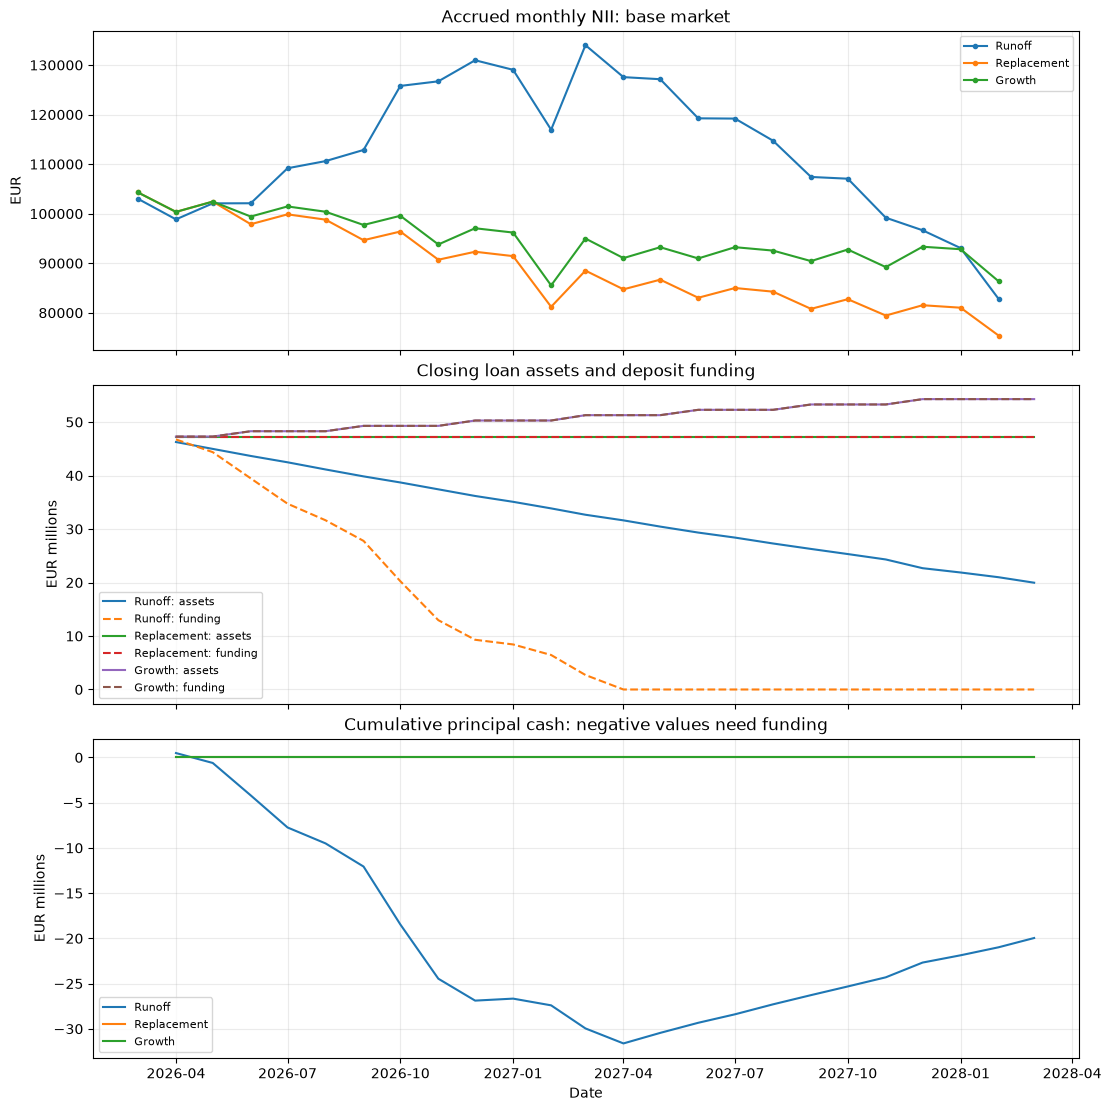

In [14]:
base = results[("Base", "Growth")]
display(base.monthly)

fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True, constrained_layout=True)
for mode in modes:
    monthly = results[("Base", mode)].monthly
    axes[0].plot(pd.to_datetime(monthly.period_start), monthly.nii, marker=".", label=mode)
    axes[1].plot(pd.to_datetime(monthly.period_end), monthly.asset_balance / 1e6, label=f"{mode}: assets")
    axes[1].plot(pd.to_datetime(monthly.period_end), monthly.liability_balance / 1e6, linestyle="--", label=f"{mode}: funding")
    axes[2].plot(pd.to_datetime(monthly.period_end), monthly.cumulative_principal_cash / 1e6, label=mode)
axes[0].set(title="Accrued monthly NII: base market", ylabel="EUR")
axes[1].set(title="Closing loan assets and deposit funding", ylabel="EUR millions")
axes[2].set(title="Cumulative principal cash: negative values need funding", ylabel="EUR millions", xlabel="Date")
for axis in axes:
    axis.legend(loc="best", fontsize=8)
    axis.grid(alpha=0.25)
plt.show()

## Follow income back to its source cohorts

We use `income_detail` to split earned interest by segment and by existing,
replacement or planned business. `productions` shows when each new cohort
starts, its amount, initial rate and maturity. For a floating contract,
`initial_rate` is the origination quote; later coupons still reset to the index.

`balances` explains the segment movements month by month, while `cashflows`
keeps each cohort's full-life coupon and principal receipts, including payments
beyond the reporting horizon. Initial production advances remain in the balance
ledger rather than appearing as income.

The final comparison links rate changes to fixed-loan prepayment volumes.
Lower rates increase refinancing incentives in this book, which changes the
amount of replacement lending as well as its coupon. That effect combines
with floating resets and deposit renewal rates in the scenario NII curves.

origin,existing,planned,replacement
segment,,,
Fixed loans,"2,070,166.30",0.00,"793,721.47"
Floating loans,"1,226,938.97","225,418.80","585,264.26"
Term funding,"-600,929.18","-46,135.44","-1,975,311.62"


,date,segment,origin,cohort,template,amount,quote_type,par_quote,commercial_margin,contract_rate_or_spread,initial_rate,par_error_bp,maturity_date
0,2026-03-10,Fixed loans,replacement,replacement-0301,24m fixed lending,"149,018.36",fixed_coupon,2.9048%,1.4000%,4.3048%,4.3048%,0.00000007,2028-03-10
1,2026-03-10,Floating loans,replacement,replacement-0302,24m floating lending,"125,225.45",floating_spread,-0.0303%,1.5000%,1.4697%,4.2093%,0.00000002,2028-03-10
2,2026-03-20,Fixed loans,replacement,replacement-0303,24m fixed lending,"272,465.90",fixed_coupon,2.9116%,1.4000%,4.3116%,4.3116%,0.00000003,2028-03-20
3,2026-03-20,Floating loans,replacement,replacement-0304,24m floating lending,"134,160.29",floating_spread,-0.0315%,1.5000%,1.4685%,4.2137%,-0.00000003,2028-03-20
4,2026-04-01,Fixed loans,replacement,replacement-0305,24m fixed lending,"216,490.58",fixed_coupon,2.9198%,1.4000%,4.3198%,4.3198%,-0.00000004,2028-04-01
5,2026-04-01,Floating loans,replacement,replacement-0306,24m floating lending,"125,904.62",floating_spread,-0.0329%,1.5000%,1.4671%,4.2185%,-0.00000008,2028-04-01
6,2026-04-01,Term funding,replacement,replacement-0307,3m term funding,"536,577.83",fixed_coupon,2.7897%,-0.4000%,2.3897%,2.3897%,-0.00000000,2026-07-01
7,2026-04-10,Fixed loans,replacement,replacement-0308,24m fixed lending,"299,592.72",fixed_coupon,2.9260%,1.4000%,4.3260%,4.3260%,0.00000009,2028-04-10
8,2026-04-10,Floating loans,replacement,replacement-0309,24m floating lending,"155,190.89",floating_spread,-0.0341%,1.5000%,1.4659%,4.2223%,-0.00000000,2028-04-10
9,2026-04-10,Term funding,replacement,replacement-0310,3m term funding,"1,533,913.53",fixed_coupon,2.7947%,-0.4000%,2.3947%,2.3947%,-0.00000000,2026-07-10


,period_start,period_end,segment,book_side,opening_balance,scheduled_principal,prepayment,production,closing_balance
0,2026-03-01,2026-04-01,Fixed loans,asset,"28,525,412.91","518,298.17","119,676.68","637,974.84","28,525,412.91"
1,2026-04-01,2026-05-01,Fixed loans,asset,"28,525,412.91","623,917.84","248,398.46","872,316.30","28,525,412.91"
2,2026-05-01,2026-06-01,Fixed loans,asset,"28,525,412.91","583,957.56","303,425.28","887,382.84","28,525,412.91"
3,2026-06-01,2026-07-01,Fixed loans,asset,"28,525,412.91","605,979.37","278,947.34","884,926.71","28,525,412.91"
4,2026-07-01,2026-08-01,Fixed loans,asset,"28,525,412.91","721,328.25","322,629.24","1,043,957.49","28,525,412.91"
5,2026-08-01,2026-09-01,Fixed loans,asset,"28,525,412.91","681,760.05","311,283.73","993,043.77","28,525,412.91"
6,2026-09-01,2026-10-01,Fixed loans,asset,"28,525,412.91","710,326.41","268,208.85","978,535.25","28,525,412.91"
7,2026-10-01,2026-11-01,Fixed loans,asset,"28,525,412.91","826,857.36","307,623.22","1,134,480.58","28,525,412.91"
8,2026-11-01,2026-12-01,Fixed loans,asset,"28,525,412.91","791,933.04","295,476.38","1,087,409.42","28,525,412.91"


,position,accrual_start,accrual_end,expected_principal,annual_rate,day_counter,year_fraction,interest
0,fixed-0001,2026-03-01,2026-04-01,"148,584.72",6.1765%,Actual360,0.08611111,790.28
1,fixed-0001,2026-04-01,2026-05-01,"136,938.67",6.1765%,Actual360,0.08333333,704.84
2,fixed-0001,2026-05-01,2026-06-01,"125,548.00",6.1765%,Actual360,0.08611111,667.75
3,fixed-0001,2026-06-01,2026-07-01,"114,452.04",6.1765%,Actual360,0.08333333,589.10
4053,floating-0001,2026-03-01,2026-04-01,"207,417.43",4.0303%,Actual365,0.08493151,709.98
4054,floating-0001,2026-04-01,2026-04-10,"207,417.43",4.0303%,Actual365,0.02465753,206.12
4055,floating-0001,2026-04-10,2026-05-01,"199,315.82",4.0804%,Actual365,0.05753425,467.92
4056,floating-0001,2026-05-01,2026-06-01,"199,315.82",4.0804%,Actual365,0.08493151,690.74
6801,funding-0001,2026-03-01,2026-04-01,"-441,272.91",1.2189%,Actual360,0.08611111,-463.16
6802,funding-0001,2026-04-01,2026-04-20,"-441,272.91",1.2189%,Actual360,0.05277778,-283.87


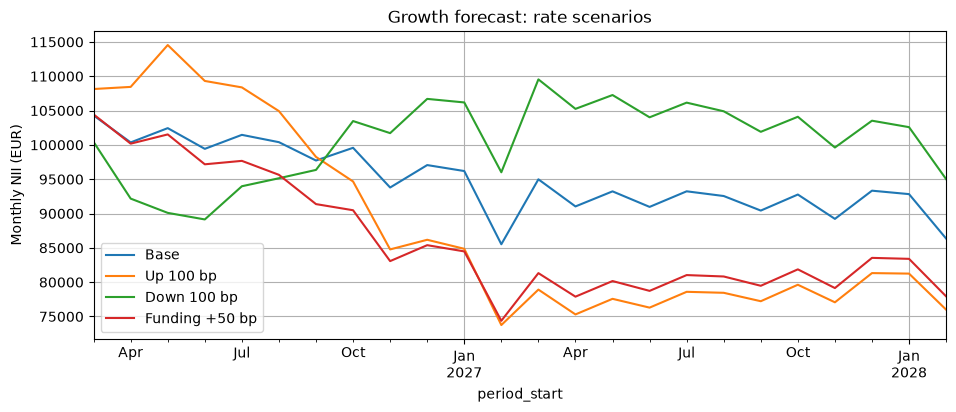

,scenario,first_year_fixed_prepayment_eur
0,Base,"2,893,448.87"
1,Up 100 bp,"1,976,828.13"
2,Down 100 bp,"3,816,771.36"
3,Funding +50 bp,"2,893,448.87"


In [15]:
attribution = base.income_detail.pivot_table(
    index="segment", columns="origin", values="interest", aggfunc="sum", fill_value=0,
)
display(attribution)
display(base.productions.head(12).style.format({
    "amount": "{:,.2f}", "par_quote": "{:.4%}", "commercial_margin": "{:.4%}",
    "contract_rate_or_spread": "{:.4%}", "initial_rate": "{:.4%}",
    "par_error_bp": "{:.8f}",
}))
display(base.balances.head(9))
display(base.income_detail.loc[:, [
    "position", "accrual_start", "accrual_end", "expected_principal", "annual_rate",
    "day_counter", "year_fraction", "interest",
]].groupby(base.income_detail.segment, sort=False).head(4).style.format({
    "expected_principal": "{:,.2f}", "annual_rate": "{:.4%}",
    "year_fraction": "{:.8f}", "interest": "{:,.2f}",
}))

scenario_income = pd.DataFrame({
    scenario: results[(scenario, "Growth")].monthly.nii.to_numpy()
    for scenario in scenario_shocks
}, index=pd.to_datetime(base.monthly.period_start))
scenario_income.plot(figsize=(11, 4), title="Growth forecast: rate scenarios", ylabel="Monthly NII (EUR)", grid=True)
plt.show()

pd.DataFrame([
    {"scenario": scenario, "first_year_fixed_prepayment_eur":
     result.balances.query("segment == 'Fixed loans'").iloc[:12].prepayment.sum()}
    for (scenario, mode), result in results.items() if mode == "Runoff"
])